# IND320 Project part 3

Niclas

GitHub repository: https://github.com/karlsenniclas-ops/IND320-project

Streamlit app: https://ind320-project-niclas.streamlit.app

The work for this part is on the `part3` branch and is merged into `main` after peer review and feedback.

## Log

In part 3 I found the electricity and precipitation areas from NVE, downloaded ERA5 weather data from open-meteo, and added outliers, anomalies, STL and a spectrogram to both the notebook and the Streamlit app.

The price areas NO1-NO5 are EL 1-5 in the magasinstatistikk. For the precipitation areas I used NVE's regions, where RS and RØ together are VASS 1, RV is VASS 2, and RM and RN together are VASS 3. I could not find a download button for these layers in NVE Atlas, but they come from NVE's map service, so the notebook downloads them with geopandas and saves them as shapefiles. I then sampled 1000 random locations in each area and in all of Norway.

The open-meteo API counts every location, 10 variables and 14 days as one call, and the free limit is 10 000 calls per day, so downloading 1000 locations for a whole year was not possible. ERA5 only has one value per 0,25 degree grid cell, so I round the locations to the nearest cell, download each cell once and weight it by the number of locations in it. For NO3 the 1000 locations became 310 cells. The function waits a minute between requests to stay under the limit, so NO3 for 2024 takes about 7 minutes, and the notebook saves the result to a file.

I tried to follow the lecture notes for the methods. The SPC function uses the DCT high-pass filter and the median and MAD of the SATV. Precipitation is skewed, so with the defaults 7,4 % of the hours are outliers, mostly heavy rain. For LOF I added the observation number as a second column like in the lecture, and 1 % gives 88 hours. STL and the spectrogram use the degree of filling for EL 3.

In the app the pages are now grouped into reservoirs, weather and electricity flows. After the feedback from part 2, the NVE data is downloaded once and cached, so changing the period no longer downloads it again, and the PDFs are in a pdfs folder. The area selector in the sidebar is global, so the weather data follows the area chosen for the reservoirs, while the year is a local setting on the weather page. The download is a hidden part of the app with a spinner and a cache, and it uses 200 of the 1000 locations so it takes a minute or two. The new pages use tabs.

## AI usage

I used Claude as help during this part, mostly to find the NVE map layers for the areas, and to work out how to stay within open-meteo's limits. I ran the notebook myself and checked that the outputs and plots before handing it in.

## Imports

In [1]:
# Packages used in this notebook (geopandas is needed for the shapefiles: pip install geopandas)
%matplotlib inline
import os
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats
from scipy.fft import dct, idct
from scipy.signal import stft
from shapely import contains_xy
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

## Electricity areas and precipitation areas

The magasinstatistikk has the electricity areas EL 1-5, the watercourse areas VASS 1-3 (VASS 4 has no data) and all of Norway (NO 0). The matching map layers in NVE Atlas are the price areas NO1-NO5 (EL 1-5) and NVE's regions. East is split into RS and RØ, so VASS 1 is RS + RØ. VASS 2 is RV. North is split into RM and RN, so VASS 3 is RM + RN.

The layers come from NVE's map service. The first time, they are downloaded and saved as shapefiles in `data/shapefiles`, and after that the shapefiles are read.

In [2]:
# The two map layers from NVE (the same as in NVE Atlas), downloaded once and saved as shapefiles
NVE_MAP = "https://kart.nve.no/enterprise/rest/services"
QUERY = "/query?where=1%3D1&outFields=*&outSR=4326&f=geojson"

if not os.path.exists("../data/shapefiles/price_areas.shp"):
    os.makedirs("../data/shapefiles", exist_ok=True)
    price_areas = gpd.read_file(NVE_MAP + "/Nettomraader/MapServer/0" + QUERY)
    price_areas[["budomr", "geometry"]].to_file("../data/shapefiles/price_areas.shp")
    nve_regions = gpd.read_file(NVE_MAP + "/Mapservices/Administrasjon2/MapServer/0" + QUERY)
    nve_regions[["REGION", "geometry"]].to_file("../data/shapefiles/nve_regions.shp")

# Read the shapefiles
price_areas = gpd.read_file("../data/shapefiles/price_areas.shp")
nve_regions = gpd.read_file("../data/shapefiles/nve_regions.shp")
print(price_areas["budomr"].tolist())
print(nve_regions["REGION"].tolist())

['NO 1', 'NO 2', 'NO 3', 'NO 4', 'NO 5']
['RV', 'RM', 'RN', 'RØ', 'RS']


### Random locations

A polygon is made for each area, and 1000 random locations are sampled inside it. All of Norway (NO0) is included so the app also has weather for NO.

In [3]:
# One polygon per area. East (VASS 1) is RS + RØ and the north (VASS 3) is RM + RN
areas = {}
for i in range(1, 6):
    areas[f"NO{i}"] = price_areas[price_areas["budomr"] == f"NO {i}"].union_all()
areas["VASS1"] = nve_regions[nve_regions["REGION"].isin(["RS", "RØ"])].union_all()
areas["VASS2"] = nve_regions[nve_regions["REGION"] == "RV"].union_all()
areas["VASS3"] = nve_regions[nve_regions["REGION"].isin(["RM", "RN"])].union_all()
areas["NO0"] = price_areas.union_all()  # all of Norway


def sample_points(area, n=1000, seed=320):
    """n random locations inside an area: random points in the bounding box, keeping the first n inside."""
    rng = np.random.default_rng(seed)
    min_lon, min_lat, max_lon, max_lat = area.bounds
    lon = rng.uniform(min_lon, max_lon, 20000)
    lat = rng.uniform(min_lat, max_lat, 20000)
    inside = contains_xy(area, lon, lat)
    return lon[inside][:n], lat[inside][:n]


# 1000 locations per area, saved so the Streamlit app can use the same locations
rows = []
for region, area in areas.items():
    lon, lat = sample_points(area)
    rows.append(pd.DataFrame({"region": region, "lon": lon.round(4), "lat": lat.round(4)}))
region_points = pd.concat(rows)
region_points.to_csv("../data/region_points.csv", index=False)
region_points["region"].value_counts()

region
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
VASS1    1000
VASS2    1000
VASS3    1000
NO0      1000
Name: count, dtype: int64

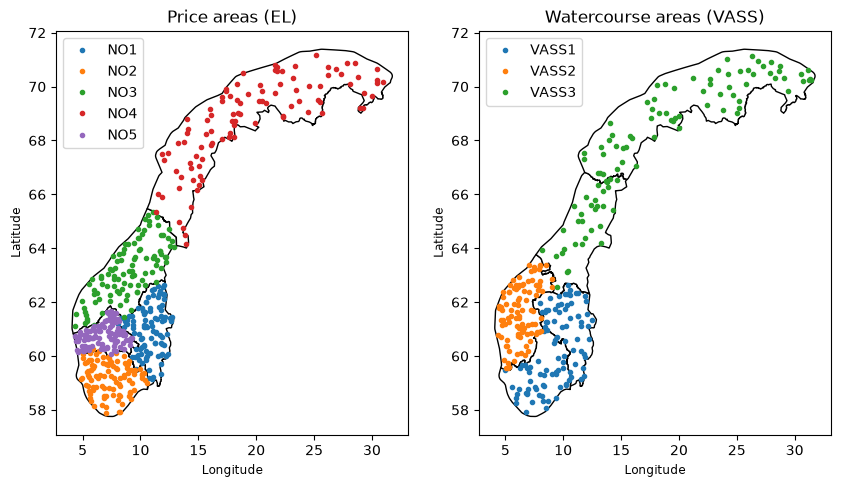

In [4]:
# Check of the areas and every 10th location
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
price_areas.plot(ax=axes[0], color="white", edgecolor="black")
nve_regions.plot(ax=axes[1], color="white", edgecolor="black")
for region in ["NO1", "NO2", "NO3", "NO4", "NO5"]:
    points = region_points[region_points["region"] == region].iloc[::10]
    axes[0].plot(points["lon"], points["lat"], ".", label=region)
for region in ["VASS1", "VASS2", "VASS3"]:
    points = region_points[region_points["region"] == region].iloc[::10]
    axes[1].plot(points["lon"], points["lat"], ".", label=region)
for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.legend()
axes[0].set_title("Price areas (EL)")
axes[1].set_title("Watercourse areas (VASS)")
plt.show()

## Weather data from open-meteo

The ERA5 reanalysis is downloaded from open-meteo's historical weather API. The function takes a region and a time interval, looks up the 1000 locations of the region and returns the hourly values averaged over the locations.

The free API allows 600 calls per minute and 10 000 per day, and every location, 10 variables and 14 days count as one call. 1000 locations for a year would use the whole day. ERA5 has one value per 0,25 degree grid cell, so the locations are rounded to the nearest cell, each cell is downloaded once and weighted by the number of locations in it. This gives the same average with far fewer calls.

The same function is in `weather.py`, which the Streamlit app uses.

In [5]:
# open-meteo's historical weather API, models=era5 gives the ERA5 reanalysis
ERA5_URL = "https://archive-api.open-meteo.com/v1/archive"

# Hourly properties to download
VARIABLES = "temperature_2m,precipitation,snowfall,wind_speed_10m"

# The locations sampled above
POINTS_FILE = "../data/region_points.csv"


def download_era5(region, start, end, n_points=1000, points_file=POINTS_FILE):
    """Hourly ERA5 weather for a region, averaged over the sampled locations.

    region is a name from the points file, e.g. "NO3". start and end are dates like "2024-01-01".
    ERA5 has one value per 0.25 degree grid cell, so locations in the same cell get the same data.
    To use fewer API calls, each cell is downloaded once and weighted by the number of locations in it.
    """
    points = pd.read_csv(points_file)
    points = points[points["region"] == region].head(n_points)

    # Round the locations to the nearest grid cell and count the locations in each cell
    cells = (points[["lat", "lon"]] / 0.25).round() * 0.25
    cells = cells.value_counts().reset_index()

    total = 0
    for i in range(0, len(cells), 50):
        # 50 cells per request, given as comma separated lists
        batch = cells.iloc[i:i + 50]
        params = {
            "latitude": ",".join(batch["lat"].astype(str)),
            "longitude": ",".join(batch["lon"].astype(str)),
            "start_date": start,
            "end_date": end,
            "hourly": VARIABLES,
            "models": "era5",
            "wind_speed_unit": "ms",
        }
        response = requests.get(ERA5_URL, params=params, timeout=120)
        response.raise_for_status()
        locations = response.json()
        if isinstance(locations, dict):  # a single location is not returned as a list
            locations = [locations]

        # Add the hourly values of each cell, weighted by the number of locations in the cell
        for location, count in zip(locations, batch["count"]):
            hourly = pd.DataFrame(location["hourly"]).set_index("time")
            total = total + hourly * count

        # The free API allows 600 calls per minute, and 50 cells for one year count as about 520 calls
        if i + 50 < len(cells):
            time.sleep(60)

    weather = total / cells["count"].sum()
    weather.index = pd.to_datetime(weather.index)
    return weather

### NO3, 2024

The download takes about 7 minutes, so the result is saved to a file and read from there when the notebook is run again.

In [6]:
# Download once, then read the saved file
if os.path.exists("../data/era5_NO3_2024.csv"):
    weather = pd.read_csv("../data/era5_NO3_2024.csv", index_col="time", parse_dates=True)
else:
    weather = download_era5("NO3", "2024-01-01", "2024-12-31")
    weather.to_csv("../data/era5_NO3_2024.csv")

weather.head()

,temperature_2m,precipitation,snowfall,wind_speed_10m
time,,,,
2024-01-01 00:00:00,-3.5389,0.0038,0.0021,7.02173
2024-01-01 01:00:00,-3.6713,0.0031,0.0021,7.09907
2024-01-01 02:00:00,-3.6432,0.0030,0.0021,7.18027
2024-01-01 03:00:00,-3.6734,0.0030,0.0021,7.21289
2024-01-01 04:00:00,-3.6153,0.0030,0.0021,7.26579


In [7]:
# Summary of the downloaded properties
weather.describe()

,temperature_2m,precipitation,snowfall,wind_speed_10m
count,8784.000000,8784.000000,8784.000000,8784.000000
mean,5.899683,0.204904,0.020951,4.156468
std,6.603831,0.273062,0.048513,1.642536
min,-11.133000,0.000000,0.000000,1.008370
25%,1.416125,0.015800,0.000000,2.923983
50%,5.573650,0.102200,0.000140,3.831550
75%,11.180300,0.289025,0.015890,5.137535
max,22.255900,2.625100,0.810880,12.907050


## Outliers and anomalies

### Precipitation

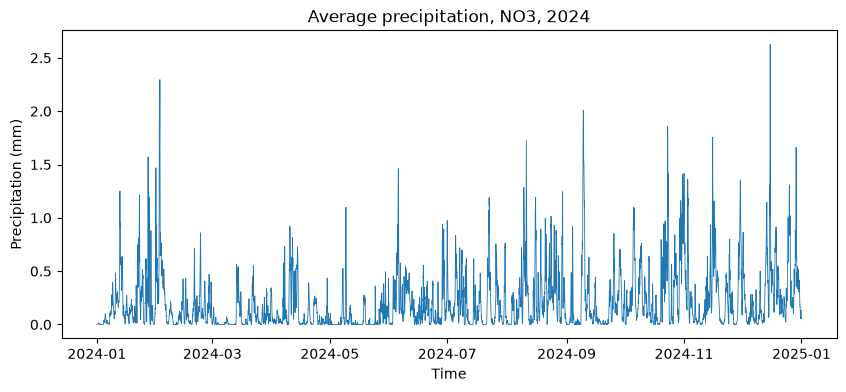

In [8]:
# Average precipitation over the locations in NO3
fig = plt.figure(figsize=(10, 4))
plt.plot(weather.index, weather["precipitation"], linewidth=0.6)
plt.xlabel("Time")
plt.ylabel("Precipitation (mm)")
plt.title("Average precipitation, NO3, 2024")
plt.show()

The slow variation is removed with a high-pass filter using the Discrete Cosine Transform, as in the lecture notes: the DCT coefficients with a frequency below the cut-off are set to zero and the signal is transformed back. What is left is the seasonally adjusted variation (SATV). The SPC boundaries are the median of the SATV +- a number of robust standard deviations (1,4826 * MAD) for the whole year. The SATV is only used to find the boundaries and outliers. The boundaries are drawn on top of the slow variation, so they can be shown together with the precipitation.

Defaults: cut-off 12 cycles per year (variation slower than about a month is removed) and 3 standard deviations.

In [9]:
def spc_outliers(series, cutoff=12, n_std=3):
    """Outliers in an hourly series with Statistical Process Control (SPC).

    A DCT high-pass filter removes all frequencies below cutoff (cycles per year). What is left is the
    seasonally adjusted variation (SATV). The boundaries are the median of the SATV +/- n_std robust
    standard deviations (1.4826 * MAD) for the whole period. Returns the plot, the outliers and a summary.
    """
    values = series.values
    N = len(values)

    # Frequency axis in cycles per year. One hour is 1/(365*24) year (2* because of the DCT definition)
    dt = 1 / (365 * 24)
    W = np.linspace(0, 1 / (2 * dt), N)

    # High-pass filter: remove the low frequencies and transform back to get the SATV
    fourier_signal = dct(values, type=1, norm="forward")
    fourier_signal[W < cutoff] = 0
    satv = idct(fourier_signal, type=1, norm="forward")
    trend = values - satv  # the slow variation that was removed

    # Robust statistics of the SATV
    median = np.median(satv)
    sd = 1.4826 * stats.median_abs_deviation(satv)

    # The boundaries follow the slow variation, so they can be drawn on top of the original series
    upper = trend + median + n_std * sd
    lower = trend + median - n_std * sd
    is_outlier = (values > upper) | (values < lower)

    fig = plt.figure(figsize=(10, 4))
    plt.plot(series.index, values, linewidth=0.6, label=series.name)
    plt.plot(series.index, upper, color="black", linestyle="--", label="SPC boundaries")
    plt.plot(series.index, lower, color="black", linestyle="--")
    plt.plot(series.index[is_outlier], values[is_outlier], "o", color="red", markersize=3, label="Outliers")
    plt.xlabel("Time")
    plt.ylabel(series.name)
    plt.title("SPC outliers")
    plt.legend()

    outliers = series[is_outlier]
    summary = pd.DataFrame({
        "outliers": [is_outlier.sum()],
        "share (%)": [100 * is_outlier.mean()],
        "SATV median": [median],
        "SATV robust SD": [sd],
    })
    return fig, outliers, summary

,outliers,share (%),SATV median,SATV robust SD
0,647,7.365665,-0.06373,0.15295


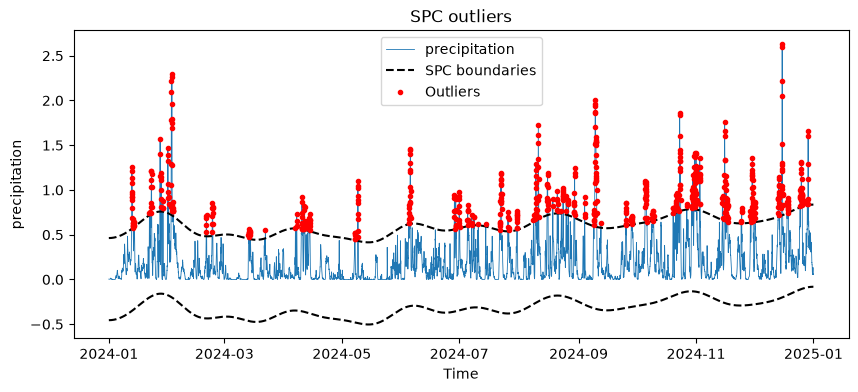

In [10]:
# Test with the default parameters
fig, outliers, summary = spc_outliers(weather["precipitation"])
summary

In [11]:
# The first outliers (precipitation in mm)
outliers.head()

time
2024-01-12 20:00:00    0.6915
2024-01-12 21:00:00    0.9264
2024-01-12 22:00:00    1.0728
2024-01-12 23:00:00    1.2104
2024-01-13 00:00:00    1.2516
Name: precipitation, dtype: float64

,outliers,share (%),SATV median,SATV robust SD
0,377,4.291894,-0.044695,0.136824


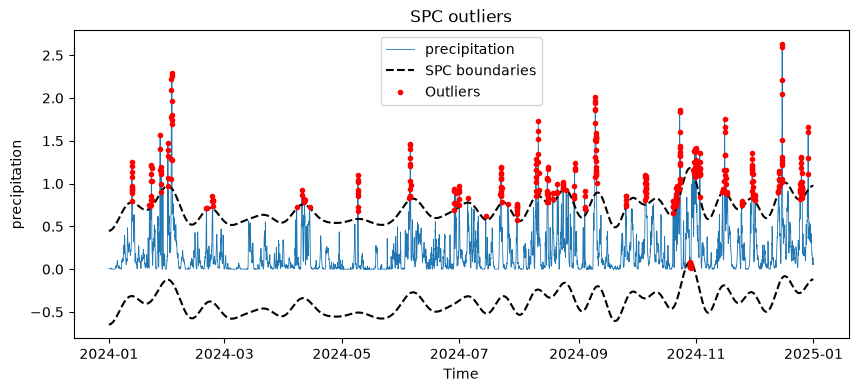

In [12]:
# Test with other parameters
fig, outliers, summary = spc_outliers(weather["precipitation"], cutoff=24, n_std=4)
summary

### Temperature

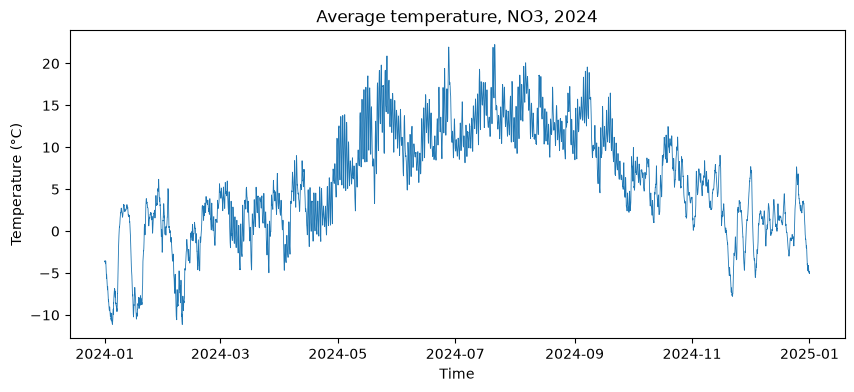

In [13]:
# Average temperature over the locations in NO3
fig = plt.figure(figsize=(10, 4))
plt.plot(weather.index, weather["temperature_2m"], linewidth=0.6)
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.title("Average temperature, NO3, 2024")
plt.show()

Anomalies are found with the Local Outlier Factor (LOF). As in the lecture notes, the observation number is added as a second column, scaled by a step size, so the method looks for values that are unusual compared to the hours around them. The proportion of outliers (contamination) is a parameter with default 1 %.

In [14]:
def lof_anomalies(series, contamination=0.01, step_size=0.005):
    """Anomalies in an hourly series with the Local Outlier Factor (LOF).

    As in the lecture notes, the observation number (times step_size) is used as a second column,
    so the anomalies are local in time. contamination is the proportion of outliers.
    Returns the plot, the anomalies and a summary.
    """
    values = series.values
    N = len(values)
    data2D = np.array([values, np.linspace(0, N * step_size, N)]).T

    lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination)
    is_anomaly = lof.fit_predict(data2D) == -1  # -1 is an outlier

    fig = plt.figure(figsize=(10, 4))
    plt.plot(series.index, values, linewidth=0.6, label=series.name)
    plt.plot(series.index[is_anomaly], values[is_anomaly], "o", color="red", markersize=3, label="Anomalies")
    plt.xlabel("Time")
    plt.ylabel(series.name)
    plt.title("LOF anomalies")
    plt.legend()

    anomalies = series[is_anomaly]
    summary = pd.DataFrame({
        "anomalies": [is_anomaly.sum()],
        "share (%)": [100 * is_anomaly.mean()],
        "lowest": [anomalies.min()],
        "highest": [anomalies.max()],
    })
    return fig, anomalies, summary

,anomalies,share (%),lowest,highest
0,88,1.001821,-1.8359,20.8902


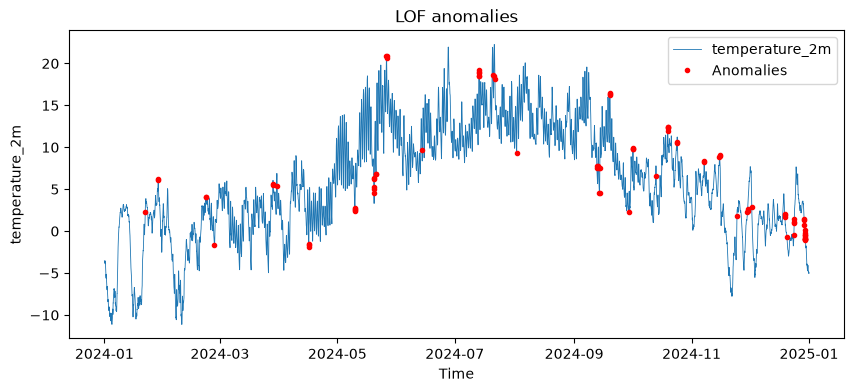

In [15]:
# Test with the default parameters
fig, anomalies, summary = lof_anomalies(weather["temperature_2m"])
summary

,anomalies,share (%),lowest,highest
0,440,5.009107,-11.1217,21.9426


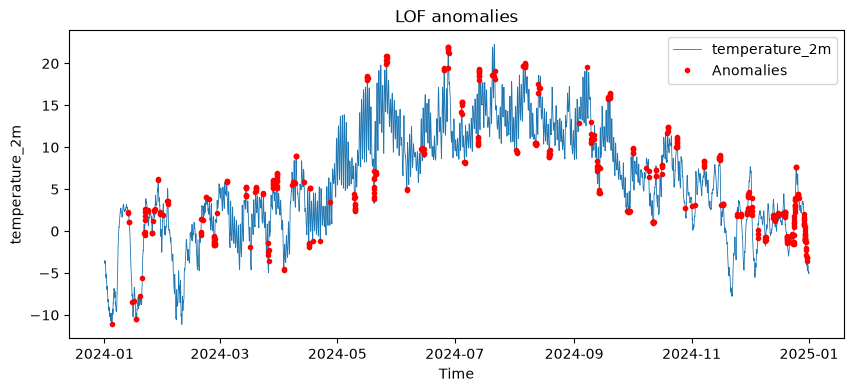

In [16]:
# Test with 5 % anomalies
fig, anomalies, summary = lof_anomalies(weather["temperature_2m"], contamination=0.05)
summary

## Seasonal-Trend decomposition using LOESS (STL)

The degree of filling for EL 3 (the same area as the weather data), downloaded from the NVE API as in part 2.

In [17]:
# Weekly reservoir data for all areas from the NVE API
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
reservoirs = pd.DataFrame(requests.get(url, timeout=60).json())
reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])

# Degree of filling for EL 3, sorted by date
el3 = reservoirs[(reservoirs["omrType"] == "EL") & (reservoirs["omrnr"] == 3)].sort_values("dato_Id")
fill_level = el3.set_index("dato_Id")["fyllingsgrad"].rename("fill_level")
print(len(fill_level), "weeks from", fill_level.index[0].date(), "to", fill_level.index[-1].date())

1661 weeks from 1995-01-08 to 2026-11-01


The period is 52 weeks. The seasonal smoother (default 7) and trend smoother (default 101) are odd numbers, where a higher number gives less change. Robust (default False) allows more individual deviation from the trend and season.

In [18]:
def stl_decomposition(series, seasonal=7, trend=101, robust=False):
    """STL decomposition of a weekly series with a period of 52 weeks.

    seasonal and trend are the lengths of the smoothers (odd numbers, high number = less change),
    robust=True allows more individual deviation from trend and season. Returns the plot.
    """
    # Fit the model and plot the series, trend, season and residual
    stl = STL(series, period=52, seasonal=seasonal, trend=trend, robust=robust)
    res = stl.fit()
    fig = res.plot()
    fig.set_size_inches(10, 7)
    return fig

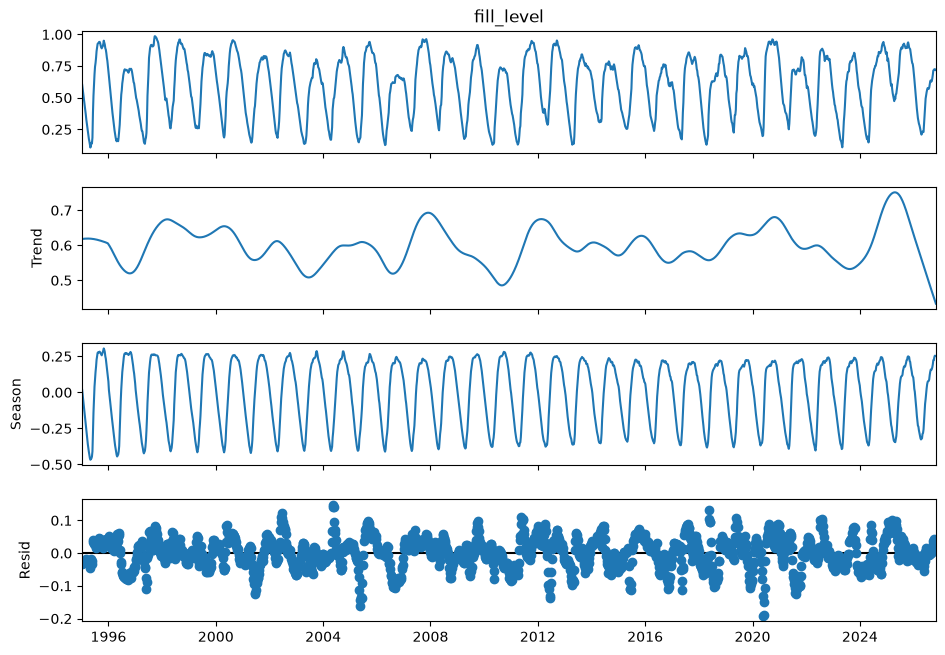

In [19]:
# Test with the default parameters
fig = stl_decomposition(fill_level)

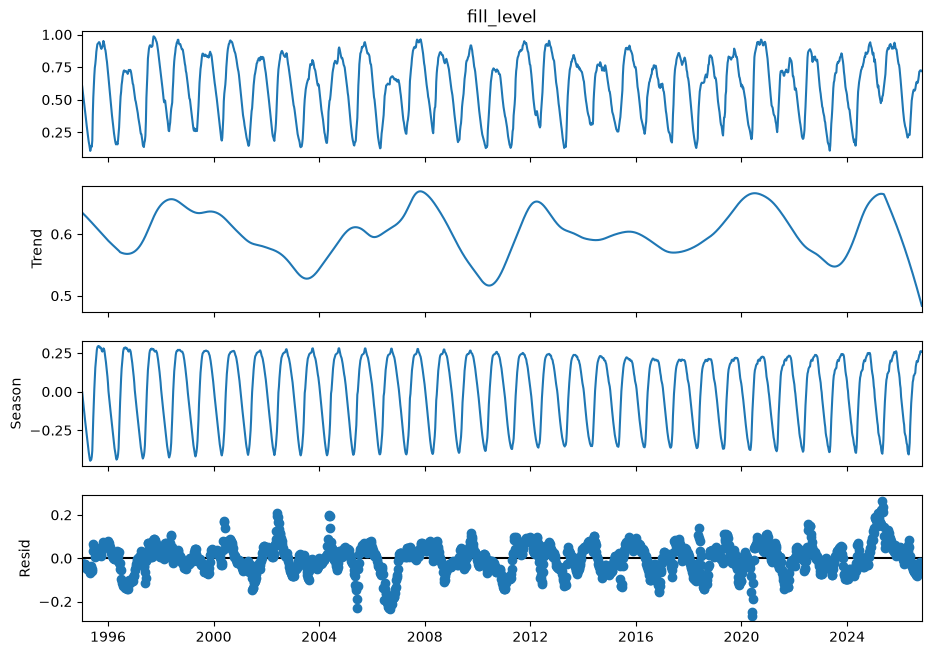

In [20]:
# Test with other parameters
fig = stl_decomposition(fill_level, seasonal=13, trend=151, robust=True)

## Spectrogram

A spectrogram of the same data with the short-time Fourier transform from the lecture notes. The data is weekly, so the sampling frequency is 52 per year and the frequency axis is in cycles per year (the yearly variation is at 1). The window length (default 52 weeks) and window overlap (default 26 weeks) are parameters.

In [21]:
def spectrogram_plot(series, window_length=52, window_overlap=26):
    """Spectrogram of a weekly series using the short-time Fourier transform.

    window_length and window_overlap are in weeks. The sampling frequency is 52 per year,
    so the frequency axis is in cycles per year. Returns the plot.
    """
    # Remove the mean so the zero frequency does not hide the rest
    values = series.values - series.values.mean()
    f, t, Zxx = stft(values, fs=52, nperseg=window_length, noverlap=window_overlap)

    fig = plt.figure(figsize=(10, 4))
    plt.pcolormesh(t, f, np.abs(Zxx), shading="gouraud")
    plt.colorbar(label="Magnitude")
    plt.xlabel(f"Years from {series.index[0].date()}")
    plt.ylabel("Frequency (cycles per year)")
    plt.title("Spectrogram")
    return fig

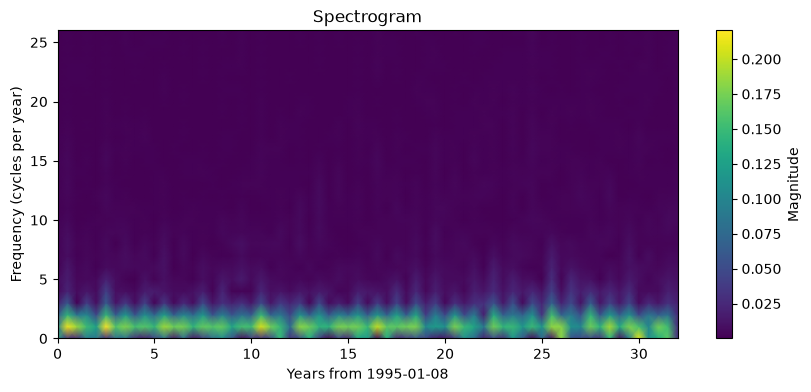

In [22]:
# Test with the default parameters
fig = spectrogram_plot(fill_level)

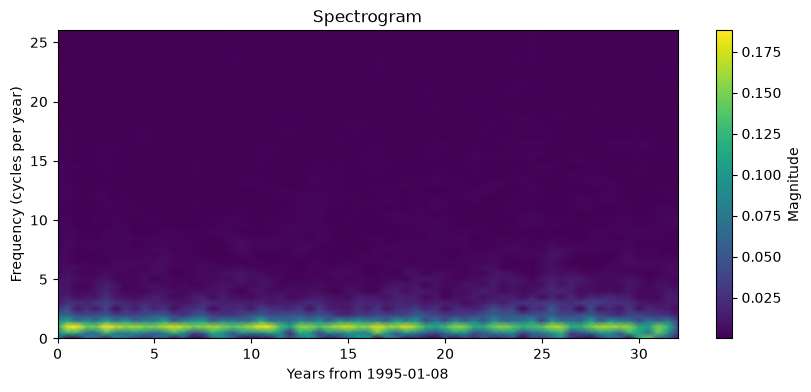

In [23]:
# Test with a longer window and more overlap
fig = spectrogram_plot(fill_level, window_length=104, window_overlap=78)